In [1]:
from configparser import Interpolation
import os 
import cv2
import numpy as np
from scipy import interpolate
os.chdir("C:\\YAPAY_ZEKA\\ressam_oct22")
path = os.getcwd()+'\\resimler\\'
folderNames = os.listdir(path)

xSample, ySample = [], []

for i, folderName in enumerate(folderNames): 
    for j, file in enumerate([f for f in os.listdir(path + folderName) if os.path.isfile(os.path.join(path + folderName, f))]):
        img = cv2.resize(cv2.imread(path + folderName + '/'+ file), (100, 100), interpolation=cv2.INTER_LINEAR)/255
        xSample.append(np.asarray(img))
        ySample.append(i)

xSample = np.array(xSample)
ySample = np.array(ySample)
print(xSample.shape)
print(ySample.shape)
print(xSample)
print(ySample)

(825, 100, 100, 3)
(825,)
[[[[0.09803922 0.16862745 0.41176471]
   [0.18431373 0.35294118 0.56470588]
   [0.10980392 0.16078431 0.44313725]
   ...
   [0.12156863 0.22352941 0.54117647]
   [0.1372549  0.17647059 0.43137255]
   [0.14117647 0.22352941 0.39215686]]

  [[0.0745098  0.1372549  0.37254902]
   [0.0745098  0.12156863 0.29411765]
   [0.08235294 0.12941176 0.41176471]
   ...
   [0.13333333 0.21960784 0.36078431]
   [0.41176471 0.52941176 0.80392157]
   [0.07058824 0.0627451  0.36078431]]

  [[0.08627451 0.20392157 0.41960784]
   [0.20392157 0.3254902  0.50196078]
   [0.21960784 0.32941176 0.52156863]
   ...
   [0.08627451 0.16862745 0.38431373]
   [0.09411765 0.2        0.37647059]
   [0.13333333 0.21568627 0.48627451]]

  ...

  [[0.21960784 0.31372549 0.41568627]
   [0.25098039 0.32941176 0.40392157]
   [0.23529412 0.34117647 0.44705882]
   ...
   [0.05882353 0.10196078 0.11764706]
   [0.09803922 0.1254902  0.1372549 ]
   [0.09803922 0.1254902  0.1372549 ]]

  [[0.18823529 0.29

In [2]:
from sklearn.model_selection import train_test_split
XTrain, XTest, yTrain, yTest= train_test_split(xSample, ySample, test_size=0.10, random_state=0)
XTrain, XVal, yTrain, yVal= train_test_split(XTrain, yTrain, test_size=0.111, random_state=0)

print(XTrain.shape)
print(XTest.shape)
print(XVal.shape)

(659, 100, 100, 3)
(83, 100, 100, 3)
(83, 100, 100, 3)


In [ ]:
import tensorflow as tf
from tensorflow.keras import datasets,layers, models

model=models.Sequential()
model.add(layers.Conv2D(100,(3,3),activation='relu',input_shape=(100,100,3)))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.BatchNormalization())
model.add(layers.Conv2D(100,(3,3),activation='relu',input_shape=(100,100,3)))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.BatchNormalization())
model.add(layers.Conv2D(100,(3,3),activation='relu',input_shape=(100,100,3)))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.BatchNormalization())
model.add(layers.Conv2D(100,(3,3),activation='relu',input_shape=(100,100,3)))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.BatchNormalization())
model.add(layers.Flatten())
model.add(layers.BatchNormalization())
model.add(layers.Dense(100, activation='relu'))
model.add(layers.Dropout(0.5))
model.add(layers.Dense(50, activation='relu'))
model.add(layers.Dropout(0.5))
model.add(layers.Dense(4, activation="softmax"))
model.summary()

model.compile(optimizer='rmsprop',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
              metrics=['accuracy'])
history = model.fit(XTrain, yTrain, epochs=100,
                    validation_data=(XVal, yVal))

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 98, 98, 100)       2800      
                                                                 
 max_pooling2d (MaxPooling2D  (None, 49, 49, 100)      0         
 )                                                               
                                                                 
 batch_normalization (BatchN  (None, 49, 49, 100)      400       
 ormalization)                                                   
                                                                 
 conv2d_1 (Conv2D)           (None, 47, 47, 100)       90100     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 23, 23, 100)      0         
 2D)                                                             
                                                        

c:\Users\feyza\anaconda3\envs\yapayzeka\lib\site-packages\keras\backend.py:5582: UserWarning: "`sparse_categorical_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Softmax activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


21/21 [==============================] - 12s 503ms/step - loss: 2.2316 - accuracy: 0.3915 - val_loss: 1.3337 - val_accuracy: 0.3494
Epoch 2/100
21/21 [==============================] - 13s 611ms/step - loss: 1.6672 - accuracy: 0.4583 - val_loss: 1.3016 - val_accuracy: 0.4578
Epoch 3/100
21/21 [==============================] - 13s 622ms/step - loss: 1.6858 - accuracy: 0.4492 - val_loss: 1.3028 - val_accuracy: 0.4578
Epoch 4/100
21/21 [==============================] - 11s 539ms/step - loss: 1.4702 - accuracy: 0.5205 - val_loss: 1.3601 - val_accuracy: 0.2289
Epoch 5/100
21/21 [==============================] - 6s 273ms/step - loss: 1.1764 - accuracy: 0.5493 - val_loss: 1.4380 - val_accuracy: 0.1446
Epoch 6/100
21/21 [==============================] - 5s 252ms/step - loss: 1.2375 - accuracy: 0.5539 - val_loss: 1.4183 - val_accuracy: 0.3373
Epoch 7/100
21/21 [==============================] - 5s 246ms/step - loss: 1.0638 - accuracy: 0.5539 - val_loss: 1.4962 - val_accuracy: 0.2169
Epoch 8

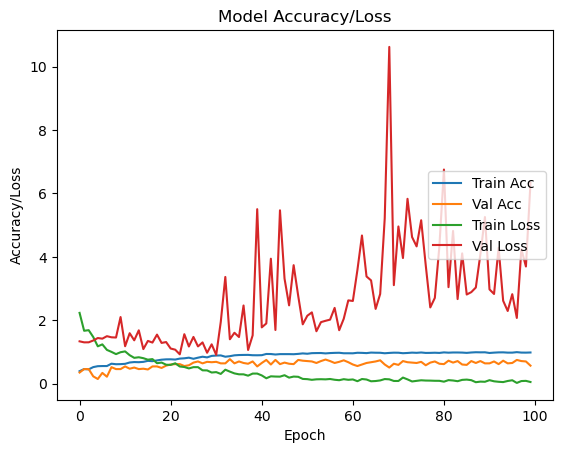

In [4]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Accuracy/Loss')
plt.ylabel('Accuracy/Loss')
plt.xlabel('Epoch')
plt.legend(['Train Acc','Val Acc', 'Train Loss', 'Val Loss'], loc='center right')
plt.show()

3/3 [==============================] - 0s 61ms/step
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        13
           1       0.77      0.84      0.80        49
           2       0.27      0.50      0.35        14
           3       1.00      0.29      0.44         7

    accuracy                           0.60        83
   macro avg       0.51      0.41      0.40        83
weighted avg       0.59      0.60      0.57        83



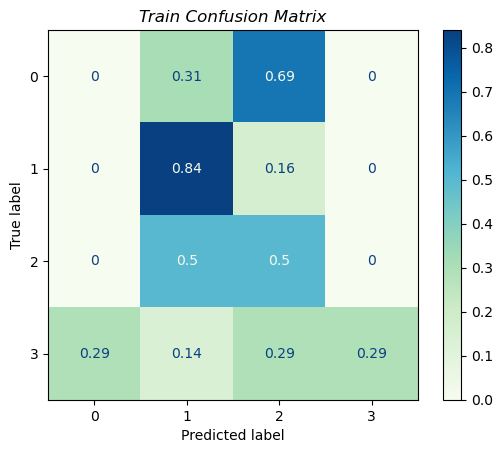

In [5]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt 
import numpy as np

yTestPred=model.predict(XTest)
yTestPred=np.argmax(yTestPred, axis=1)

print(classification_report(yTest,yTestPred))
cm=confusion_matrix(yTest,yTestPred,normalize="true").round(2)
disp=ConfusionMatrixDisplay(confusion_matrix=cm)
disp=disp.plot(cmap=plt.cm.GnBu, values_format='g')
plt.title("Train Confusion Matrix", style="italic")
plt.show()